#Q1

Consider the daily historical data of Nifty 50 stocks for the period 01/01 2014 to 31/12/2023.

Let d(i, j) = 1 - ρij^2 where ρij is the correlation coefficient between the returns of stocks Yiand Yj. Perform the following:

In [6]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

# Define Tickers
tickers = [
    "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "ICICIBANK.NS", "INFY.NS",
    "HINDUNILVR.NS", "ITC.NS", "SBIN.NS", "BHARTIARTL.NS", "KOTAKBANK.NS",
    "LT.NS", "AXISBANK.NS", "ASIANPAINT.NS", "MARUTI.NS", "TITAN.NS",
    "HCLTECH.NS", "BAJFINANCE.NS", "SUNPHARMA.NS", "ADANIENT.NS", "ULTRACEMCO.NS",
    "TATASTEEL.NS", "JSWSTEEL.NS", "GRASIM.NS", "NTPC.NS", "POWERGRID.NS",
    "ONGC.NS", "ADANIPORTS.NS", "HINDALCO.NS", "M&M.NS", "COALINDIA.NS",
    "BAJAJFINSV.NS", "NESTLEIND.NS", "CIPLA.NS", "DRREDDY.NS", "APOLLOHOSP.NS",
    "BRITANNIA.NS", "BPCL.NS", "BAJAJ-AUTO.NS", "EICHERMOT.NS", "HEROMOTOCO.NS",
    "DIVISLAB.NS", "INDUSINDBK.NS", "TECHM.NS", "WIPRO.NS", "TATACONSUM.NS"
]

# Download Data
start_date = "2014-01-01"
end_date = "2024-01-01" # Date is exclusive

print("Downloading data...")

# Use auto_adjust=True to handle the warning and get clean price data
raw_data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)
prices = raw_data["Close"]

print("\nRaw data shape:", prices.shape)

[*********************100%***********************]  45 of 45 completed



Raw data shape: (2465, 45)


1. Preprocess the data and calculate the daily returns of the Nifty 50 stocks. Construct the correlation-distance matrix.

Number of stocks retained: 45
Price data shape: (2465, 45)

Daily returns shape: (2464, 45)
Correlation-distance matrix:


Ticker,ADANIENT.NS,ADANIPORTS.NS,APOLLOHOSP.NS,ASIANPAINT.NS,AXISBANK.NS,BAJAJ-AUTO.NS,BAJAJFINSV.NS,BAJFINANCE.NS,BHARTIARTL.NS,BPCL.NS,...,RELIANCE.NS,SBIN.NS,SUNPHARMA.NS,TATACONSUM.NS,TATASTEEL.NS,TCS.NS,TECHM.NS,TITAN.NS,ULTRACEMCO.NS,WIPRO.NS
Ticker,,,,,,,,,,,,,,,,,,,,,
ADANIENT.NS,0.000000,0.683258,0.960910,0.952971,0.912345,0.949490,0.909129,0.913531,0.952327,0.925584,...,0.913127,0.863644,0.951374,0.895750,0.889790,0.975014,0.963471,0.944070,0.891433,0.969252
ADANIPORTS.NS,0.683258,0.000000,0.944411,0.924170,0.863327,0.918462,0.883344,0.889428,0.931067,0.907923,...,0.882108,0.824130,0.947388,0.867446,0.852804,0.966622,0.935641,0.921375,0.848533,0.960243
APOLLOHOSP.NS,0.960910,0.944411,0.000000,0.946294,0.943918,0.948652,0.920122,0.914933,0.974389,0.963291,...,0.950812,0.954531,0.947108,0.923084,0.945825,0.971314,0.944565,0.955445,0.918991,0.950094
ASIANPAINT.NS,0.952971,0.924170,0.946294,0.000000,0.908869,0.902118,0.888935,0.893452,0.952654,0.920667,...,0.902088,0.932686,0.970998,0.887219,0.940230,0.958690,0.953255,0.901385,0.826339,0.957864
AXISBANK.NS,0.912345,0.863327,0.943918,0.908869,0.000000,0.892449,0.788796,0.804893,0.931109,0.879662,...,0.866756,0.663761,0.958779,0.878424,0.843363,0.966200,0.937173,0.897342,0.816263,0.955696
BAJAJ-AUTO.NS,0.949490,0.918462,0.948652,0.902118,0.892449,0.000000,0.891119,0.887811,0.928324,0.926032,...,0.904263,0.909243,0.957793,0.907633,0.913521,0.954914,0.965240,0.906918,0.879407,0.949573
BAJAJFINSV.NS,0.909129,0.883344,0.920122,0.888935,0.788796,0.891119,0.000000,0.528904,0.926207,0.889110,...,0.879076,0.832572,0.953114,0.854488,0.859315,0.966821,0.937466,0.888599,0.836179,0.957888
BAJFINANCE.NS,0.913531,0.889428,0.914933,0.893452,0.804893,0.887811,0.528904,0.000000,0.937745,0.904550,...,0.884835,0.825564,0.962498,0.861047,0.884522,0.964031,0.943762,0.896777,0.853429,0.964858
BHARTIARTL.NS,0.952327,0.931067,0.974389,0.952654,0.931109,0.928324,0.926207,0.937745,0.000000,0.951969,...,0.923849,0.917330,0.971678,0.935130,0.924647,0.976486,0.970705,0.959062,0.906297,0.978069


Preprocessing Completed


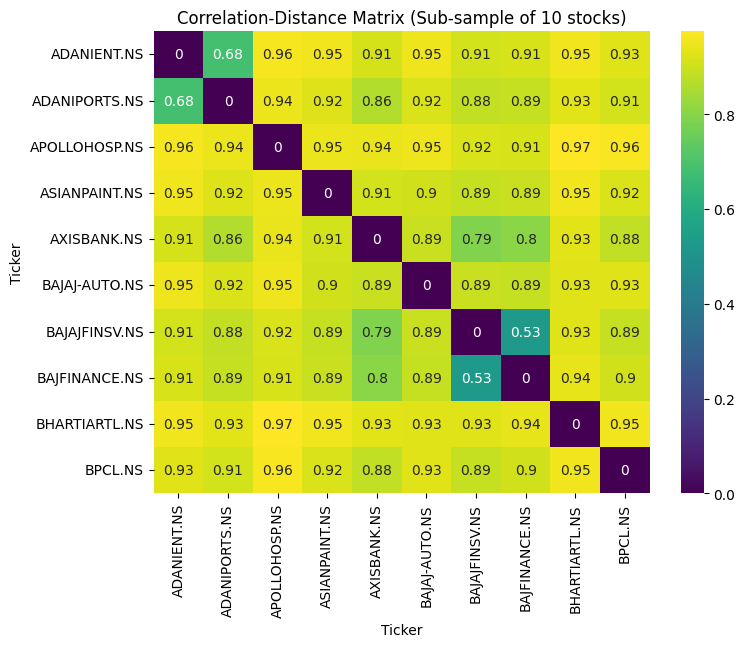

In [7]:
# Keep only columns that have data for at least 95% of the time period
min_obs = int(0.95 * len(prices))
clean_data = prices.dropna(axis=1, thresh=min_obs)
clean_data = clean_data.ffill().dropna()
print("Number of stocks retained:", clean_data.shape[1])
print("Price data shape:", clean_data.shape)

# Calculate Daily Returns (Log Returns)
returns = np.log(clean_data / clean_data.shift(1)).dropna()
print("\nDaily returns shape:", returns.shape)

# Construct Correlation-Distance Matrix
# d(i, j) = 1 - ρij^2
corr_matrix = returns.corr()
dist_matrix = 1 - (corr_matrix ** 2)

print("Correlation-distance matrix:")
display(dist_matrix)

print(f"Preprocessing Completed")

# Visualize a small part of the distance matrix
plt.figure(figsize=(8, 6))
sns.heatmap(dist_matrix.iloc[:10, :10], annot=True, cmap='viridis')
plt.title("Correlation-Distance Matrix (Sub-sample of 10 stocks)")
plt.show()

ii) Identify the 30, 35 and 40 dominant eigenvalues and corresponding eigenvectors. Express the remaining stock-return series as linear combinations of the dominant eigenvectors. Compare the reconstruction accuracy and identify the best representation.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Standardize returns for Eigen-decomposition (PCA)
scaler = StandardScaler()
scaled_returns = scaler.fit_transform(returns)

k_values = [30, 35, 40]
reconstruction_results = {}

for k in k_values:
    pca = PCA(n_components=k)
    # Principal component scores
    components = pca.fit_transform(scaled_returns)

    # Eigenvalues, Eigenvectors
    eigenvalues = pca.explained_variance_
    eigenvectors = pca.components_

    # Reconstruction
    reconstructed_data = pca.inverse_transform(components)

    # Reconstruction error
    mse = np.mean((scaled_returns - reconstructed_data) ** 2)
    rmse = np.sqrt(mse)

    # Explained variance
    explained_variance = (np.sum(pca.explained_variance_ratio_) * 100)

    reconstruction_results[k] = {
        "MSE": mse,
        "RMSE": rmse,
        "Var": explained_variance
    }

    # print Eigen values and Eigen vectors if needed!

In [ ]:
print("--- Reconstruction Accuracy Analysis ---")

for k, result in reconstruction_results.items():
    print(
        f"k = {k}: "
        f"Variance = {result['Var']:.2f}%, "
        f"MSE = {result['MSE']:.6f}, "
        f"RMSE = {result['RMSE']:.6f}"
    )

best_k = max(reconstruction_results, key=lambda x: reconstruction_results[x]['Var'])
print(f"\nBest representation is with K = {best_k} dominant eigenvectors.")

--- Reconstruction Accuracy Analysis ---
k = 30: Variance = 86.87%, MSE = 0.131252, RMSE = 0.362288
k = 35: Variance = 92.12%, MSE = 0.078775, RMSE = 0.280668
k = 40: Variance = 96.62%, MSE = 0.033828, RMSE = 0.183925

Best representation is with K = 40 dominant eigenvectors.


(iii) Perform hierarchical clustering using the correlation distance. Obtain and display the dendrogram and determine the optimal number of clusters using the criterion d(i,j) < 0.5

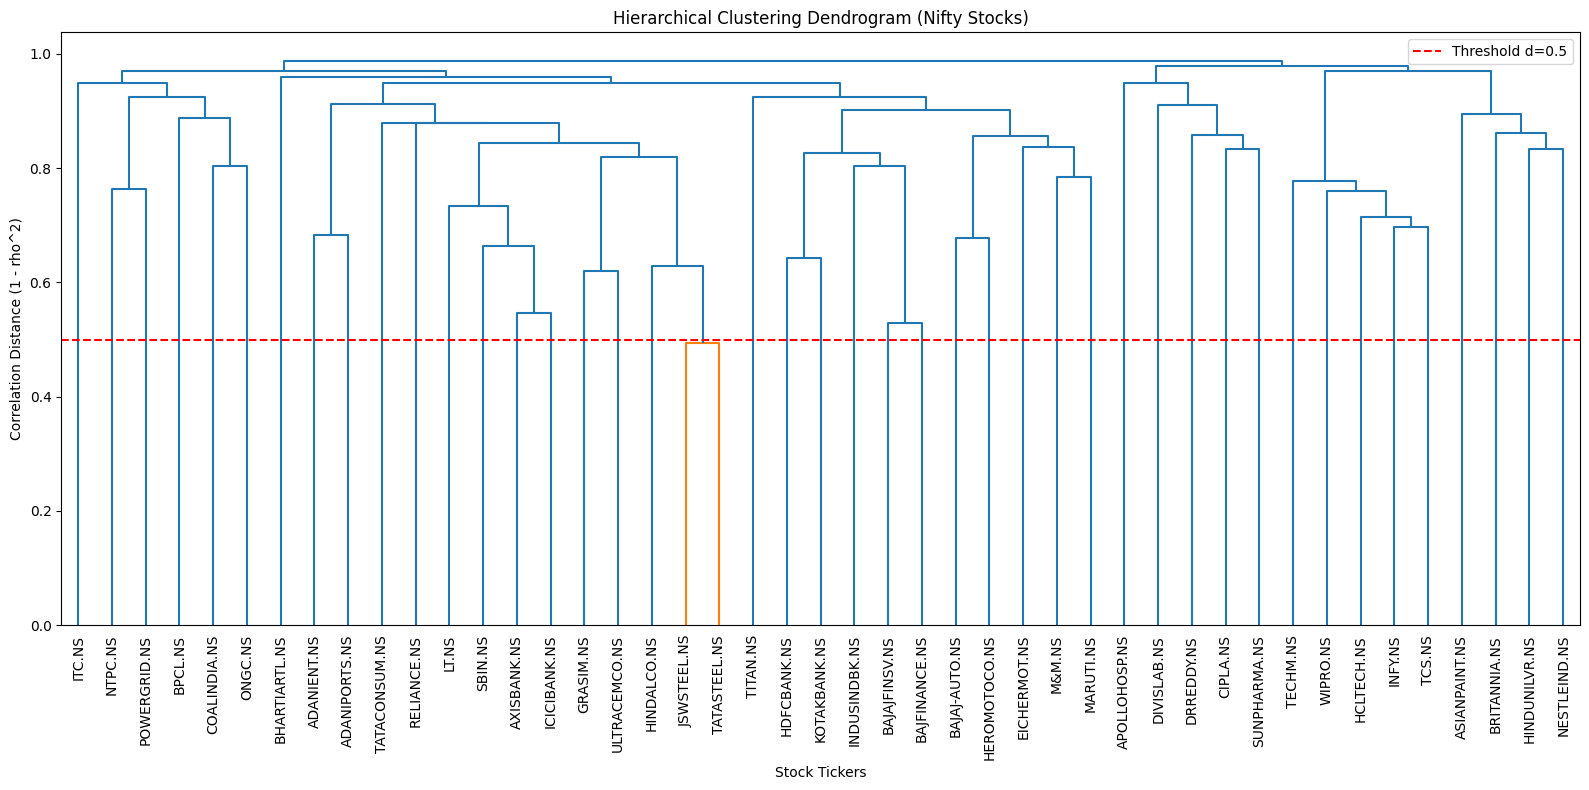

Number of clusters identified with d < 0.5: 44


In [ ]:
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import squareform

# 1. Convert the distance matrix to a condensed form
# Linkage requires a 1D array of the upper triangle of the distance matrix
condensed_dist = squareform(dist_matrix)

# 2. Perform Hierarchical Clustering
# We use 'complete' linkage to find compact, well-separated clusters
Z = linkage(condensed_dist, method='complete')

# 3. Determine the optimal number of clusters using d < 0.5
# This creates clusters where no two items in a cluster have a distance > 0.5
threshold = 0.5
cluster_labels = fcluster(Z, t=threshold, criterion='distance')

# 4. Plot the Dendrogram
plt.figure(figsize=(16, 8))
plt.title("Hierarchical Clustering Dendrogram (Nifty Stocks)")
dendrogram(
    Z,
    labels=returns.columns,
    leaf_rotation=90,
    leaf_font_size=10,
    color_threshold=threshold # This colors the clusters based on our 0.5 limit
)
plt.axhline(y=threshold, color='r', linestyle='--', label=f'Threshold d={threshold}')
plt.xlabel("Stock Tickers")
plt.ylabel("Correlation Distance (1 - rho^2)")
plt.legend()
plt.tight_layout()
plt.show()

print(f"Number of clusters identified with d < {threshold}: {len(set(cluster_labels))}")

In [ ]:
# There are total 45 stocks
# TATASTEELS.NS and JSWSTEEL.NS have correlation < 0.5 so they belong to same cluster
# Remaining, each stock belong to a seperate cluster.

(iv) Display the stocks belonging to each cluster and compare the clusters with their respective financial sectors.

In [ ]:
cluster_count = len(np.unique(cluster_labels))

print(f"Number of clusters at distance threshold {threshold}: {cluster_count}")

cluster_df = pd.DataFrame({
    "Stock": returns.columns,
    "Cluster": cluster_labels
})

print("\nSTOCKS IN EACH CLUSTER")
for cluster in sorted(cluster_df["Cluster"].unique()):
    stocks = cluster_df.loc[
        cluster_df["Cluster"] == cluster,
        "Stock"
    ].tolist()
    print(f"Cluster {cluster} ({len(stocks)} stocks): ", stocks)

Number of clusters at distance threshold 0.5: 44

STOCKS IN EACH CLUSTER
Cluster 1 (1 stocks):  ['NTPC.NS']
Cluster 2 (1 stocks):  ['POWERGRID.NS']
Cluster 3 (1 stocks):  ['COALINDIA.NS']
Cluster 4 (1 stocks):  ['ONGC.NS']
Cluster 5 (1 stocks):  ['BPCL.NS']
Cluster 6 (1 stocks):  ['ITC.NS']
Cluster 7 (1 stocks):  ['ADANIENT.NS']
Cluster 8 (1 stocks):  ['ADANIPORTS.NS']
Cluster 9 (1 stocks):  ['AXISBANK.NS']
Cluster 10 (1 stocks):  ['ICICIBANK.NS']
Cluster 11 (1 stocks):  ['SBIN.NS']
Cluster 12 (1 stocks):  ['LT.NS']
Cluster 13 (1 stocks):  ['GRASIM.NS']
Cluster 14 (1 stocks):  ['ULTRACEMCO.NS']
Cluster 15 (2 stocks):  ['JSWSTEEL.NS', 'TATASTEEL.NS']
Cluster 16 (1 stocks):  ['HINDALCO.NS']
Cluster 17 (1 stocks):  ['RELIANCE.NS']
Cluster 18 (1 stocks):  ['TATACONSUM.NS']
Cluster 19 (1 stocks):  ['HDFCBANK.NS']
Cluster 20 (1 stocks):  ['KOTAKBANK.NS']
Cluster 21 (1 stocks):  ['BAJAJFINSV.NS']
Cluster 22 (1 stocks):  ['BAJFINANCE.NS']
Cluster 23 (1 stocks):  ['INDUSINDBK.NS']
Cluster 24 (1

#Q2

Consider the same Nifty 50 stock data for 01/01/2014–31/12/2023.

In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

# Define Tickers
tickers = [
    "RELIANCE.NS", "TCS.NS", "HDFCBANK.NS", "ICICIBANK.NS", "INFY.NS",
    "HINDUNILVR.NS", "ITC.NS", "SBIN.NS", "BHARTIARTL.NS", "KOTAKBANK.NS",
    "LT.NS", "AXISBANK.NS", "ASIANPAINT.NS", "MARUTI.NS", "TITAN.NS",
    "HCLTECH.NS", "BAJFINANCE.NS", "SUNPHARMA.NS", "ADANIENT.NS", "ULTRACEMCO.NS",
    "TATASTEEL.NS", "JSWSTEEL.NS", "GRASIM.NS", "NTPC.NS", "POWERGRID.NS",
    "ONGC.NS", "ADANIPORTS.NS", "HINDALCO.NS", "M&M.NS", "COALINDIA.NS",
    "BAJAJFINSV.NS", "NESTLEIND.NS", "CIPLA.NS", "DRREDDY.NS", "APOLLOHOSP.NS",
    "BRITANNIA.NS", "BPCL.NS", "BAJAJ-AUTO.NS", "EICHERMOT.NS", "HEROMOTOCO.NS",
    "DIVISLAB.NS", "INDUSINDBK.NS", "TECHM.NS", "WIPRO.NS", "TATACONSUM.NS"
]

# Download Data
start_date = "2014-01-01"
end_date = "2024-01-01" # Date is exclusive

print("Downloading data...")

# Use auto_adjust=True to handle the warning and get clean price data
raw_data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=True)
prices = raw_data["Close"]

print("\nRaw data shape:", prices.shape)
stock_names = tickers

[*********************100%***********************]  45 of 45 completed


Raw data shape: (2465, 45)


(i) Construct the Minimum Spanning Tree (MST) using:
* Correlation distance
* Euclidean distance

(ii) Obtain the MST using both Prim's and Kruskal's algorithms for the two distance measures.

In [ ]:
# Find Correlation distance and euclidean distance (refer Q1)

from scipy.spatial.distance import pdist, squareform

# Correlation distance --> d(i, j) = 1 - ρij^2
corr_dist = returns.corr()
dist_matrix = 1 - (corr_matrix ** 2)

# Euclidean distance between stock return series
euclidean_dist = squareform(pdist(returns.T, metric='euclidean'))

# Convert to DataFrame
euclidean_dist = pd.DataFrame(
    euclidean_dist,
    index=returns.columns,
    columns=returns.columns
)

In [ ]:
import networkx as nx

def construct_msts(distance_matrix):
    stocks = distance_matrix.index.tolist()

    # Create complete graph
    G = nx.Graph()
    G.add_nodes_from(stocks)

    # Add weighted edges
    for i in range(len(stocks)):
        for j in range(i + 1, len(stocks)):
            G.add_edge(stocks[i], stocks[j],
                weight=distance_matrix.iloc[i, j]
            )

    # Prim's MST
    mst_prim = nx.minimum_spanning_tree(
        G,
        algorithm="prim",
        weight="weight"
    )

    # Kruskal's MST
    mst_kruskal = nx.minimum_spanning_tree(
        G,
        algorithm="kruskal",
        weight="weight"
    )

    return mst_prim, mst_kruskal

In [ ]:
def print_mst_results(mst, name):
    print("\n" + "="*60)
    print(name)
    print("="*60)

    print("Number of nodes:", mst.number_of_nodes())
    print("Number of edges:", mst.number_of_edges())
    print("Total MST weight:", round(mst.size(weight="weight"), 4))
    print("\nEdges:")
    for u, v, data in mst.edges(data=True):
      print(u, "--", v, ":", round(data["weight"], 4))

In [ ]:
import matplotlib.pyplot as plt

def plot_mst(mst, name, color):
    plt.figure(figsize=(14, 10))
    pos = nx.spring_layout(mst, seed=42)
    nx.draw(
        mst,
        pos,
        with_labels=True,
        node_color=color,
        node_size=1200,
        font_size=8,
        edge_color="gray"
    )
    plt.title(name)
    plt.axis("off")
    plt.show()

In [ ]:
corr_prim, corr_kruskal = construct_msts(dist_matrix)
euclidean_prim, euclidean_kruskal = construct_msts(euclidean_dist)

print_mst_results(corr_prim, "Correlation Distance - Prim's MST")
print_mst_results(corr_kruskal, "Correlation Distance - Kruskal's MST")
print_mst_results(euclidean_prim, "Euclidean Distance - Prim's MST")
print_mst_results(euclidean_kruskal, "Euclidean Distance - Kruskal's MST")


Correlation Distance - Prim's MST
Number of nodes: 45
Number of edges: 44
Total MST weight: 33.6791

Edges:
ADANIENT.NS -- ADANIPORTS.NS : 0.6833
ADANIPORTS.NS -- SBIN.NS : 0.8241
APOLLOHOSP.NS -- BAJFINANCE.NS : 0.9149
ASIANPAINT.NS -- ULTRACEMCO.NS : 0.8263
ASIANPAINT.NS -- HINDUNILVR.NS : 0.8589
AXISBANK.NS -- BAJAJFINSV.NS : 0.7888
AXISBANK.NS -- ICICIBANK.NS : 0.5463
AXISBANK.NS -- INDUSINDBK.NS : 0.7258
AXISBANK.NS -- MARUTI.NS : 0.7972
BAJAJ-AUTO.NS -- HEROMOTOCO.NS : 0.6772
BAJAJFINSV.NS -- BAJFINANCE.NS : 0.5289
BHARTIARTL.NS -- GRASIM.NS : 0.8721
BPCL.NS -- ONGC.NS : 0.8543
BRITANNIA.NS -- HINDUNILVR.NS : 0.8359
CIPLA.NS -- SUNPHARMA.NS : 0.8329
COALINDIA.NS -- ONGC.NS : 0.8035
COALINDIA.NS -- NTPC.NS : 0.8209
DIVISLAB.NS -- DRREDDY.NS : 0.88
DRREDDY.NS -- SUNPHARMA.NS : 0.8562
EICHERMOT.NS -- MARUTI.NS : 0.7859
GRASIM.NS -- ULTRACEMCO.NS : 0.6199
GRASIM.NS -- JSWSTEEL.NS : 0.7801
GRASIM.NS -- TATACONSUM.NS : 0.8394
GRASIM.NS -- SUNPHARMA.NS : 0.9125
HCLTECH.NS -- INFY.NS : 

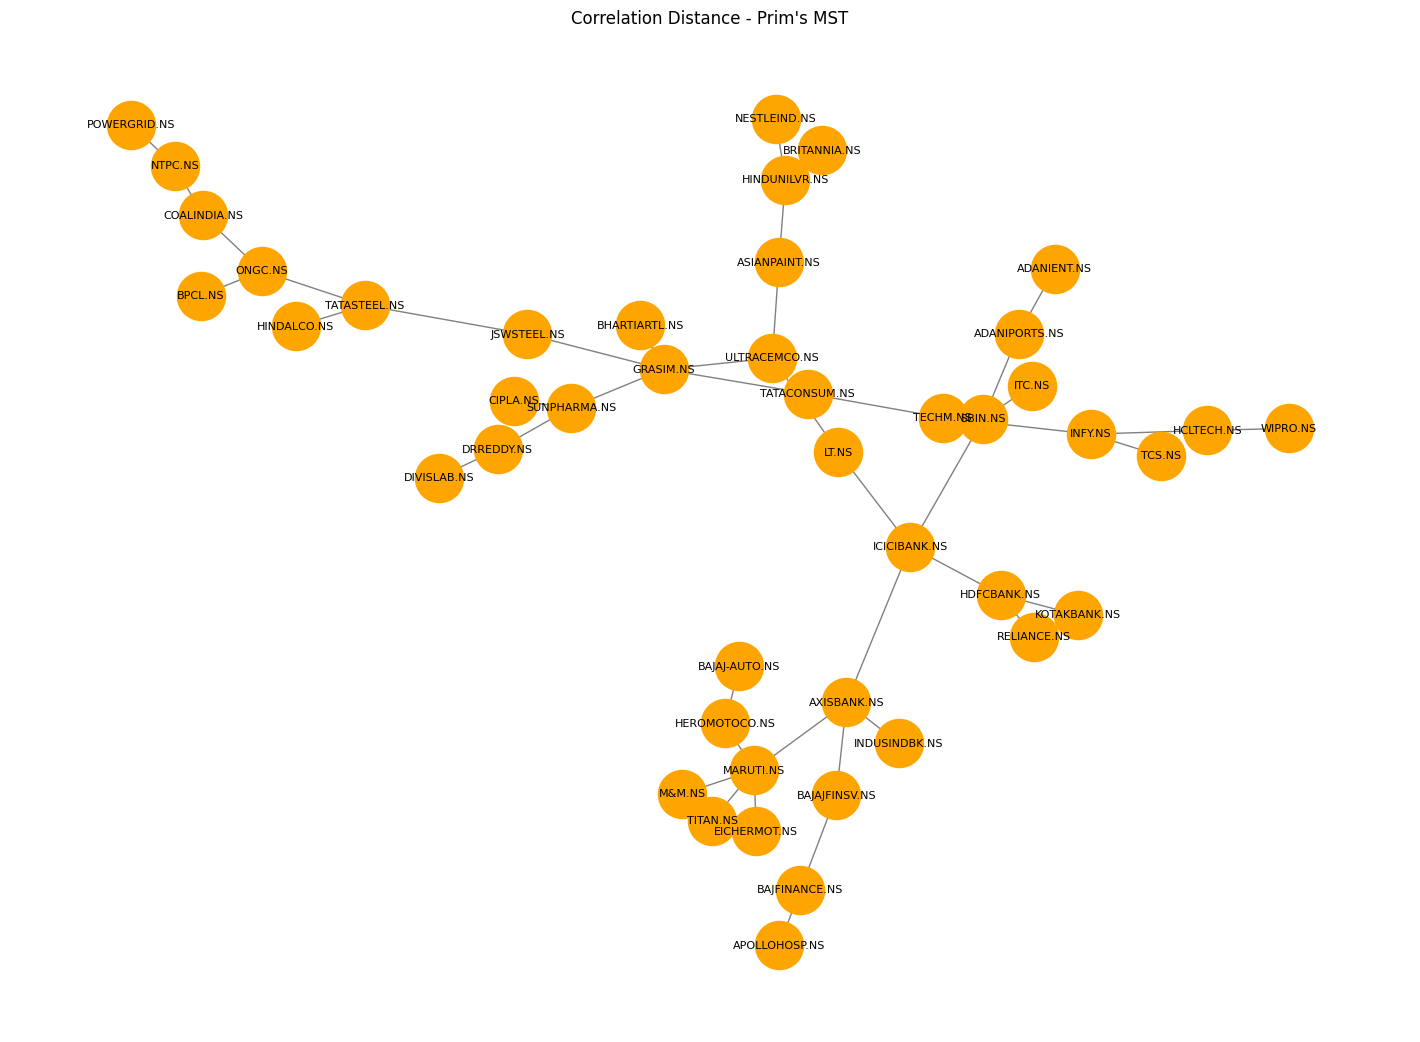

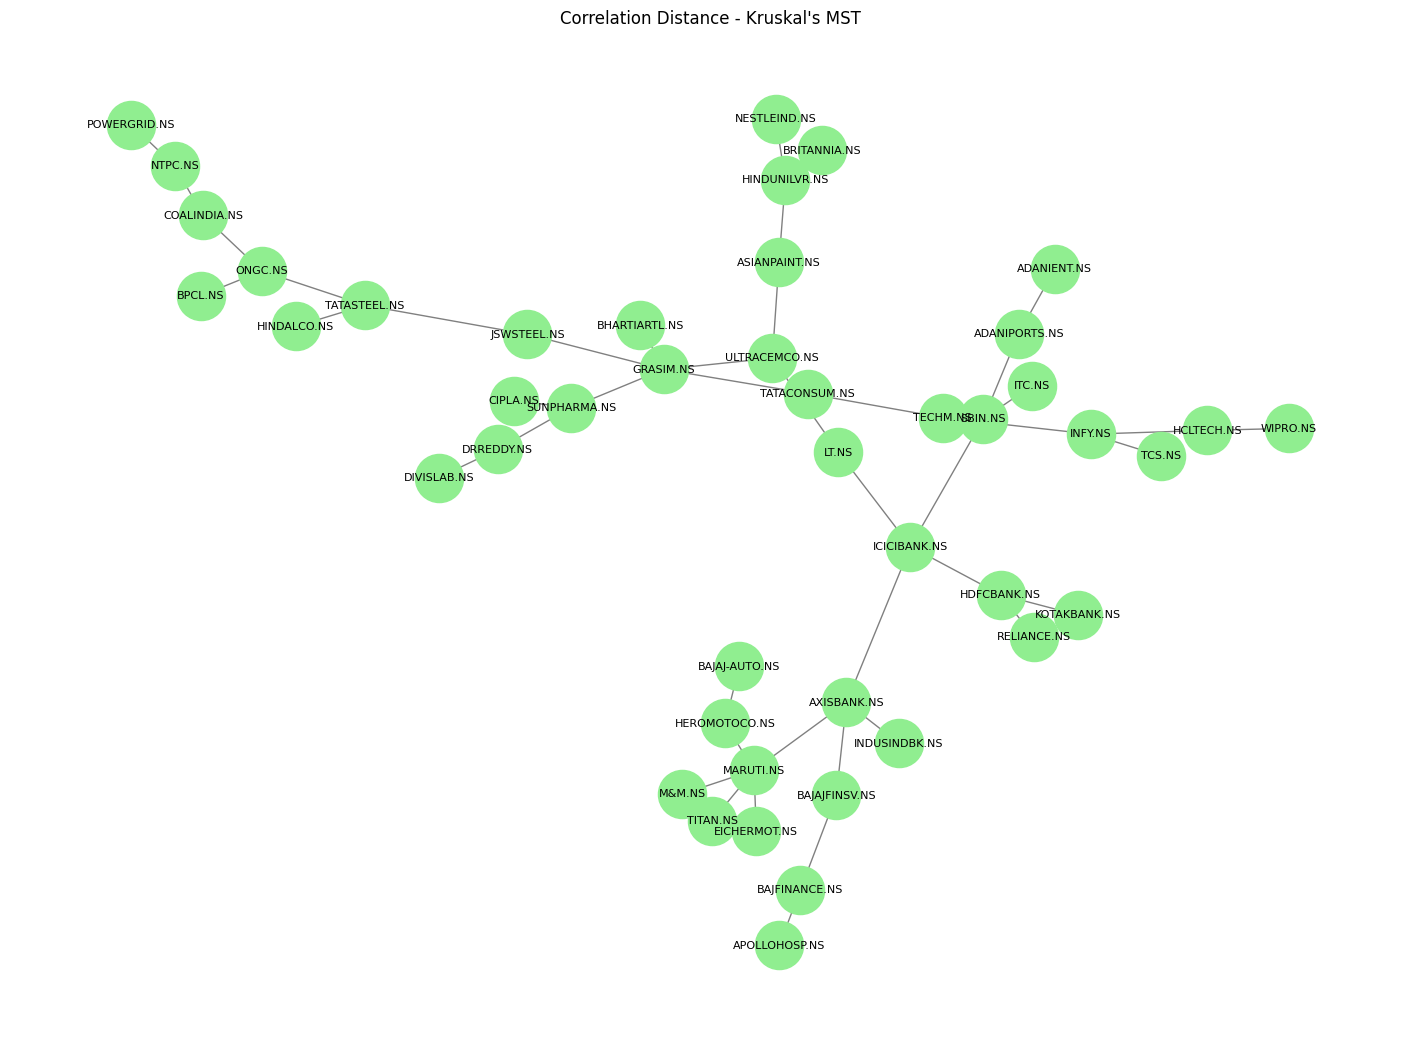

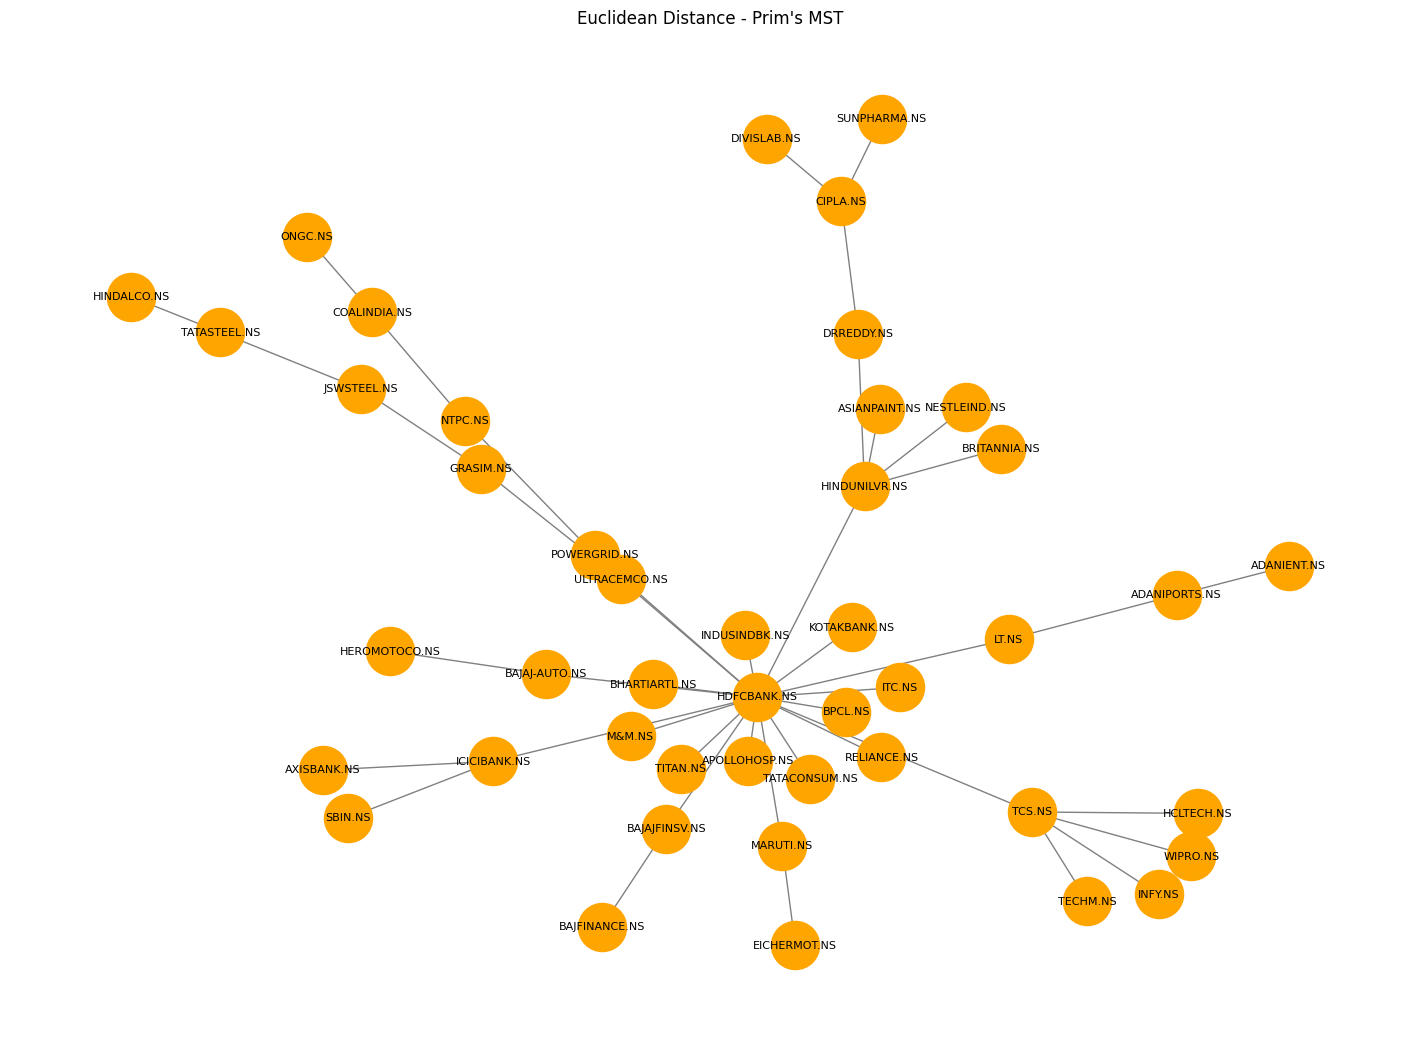

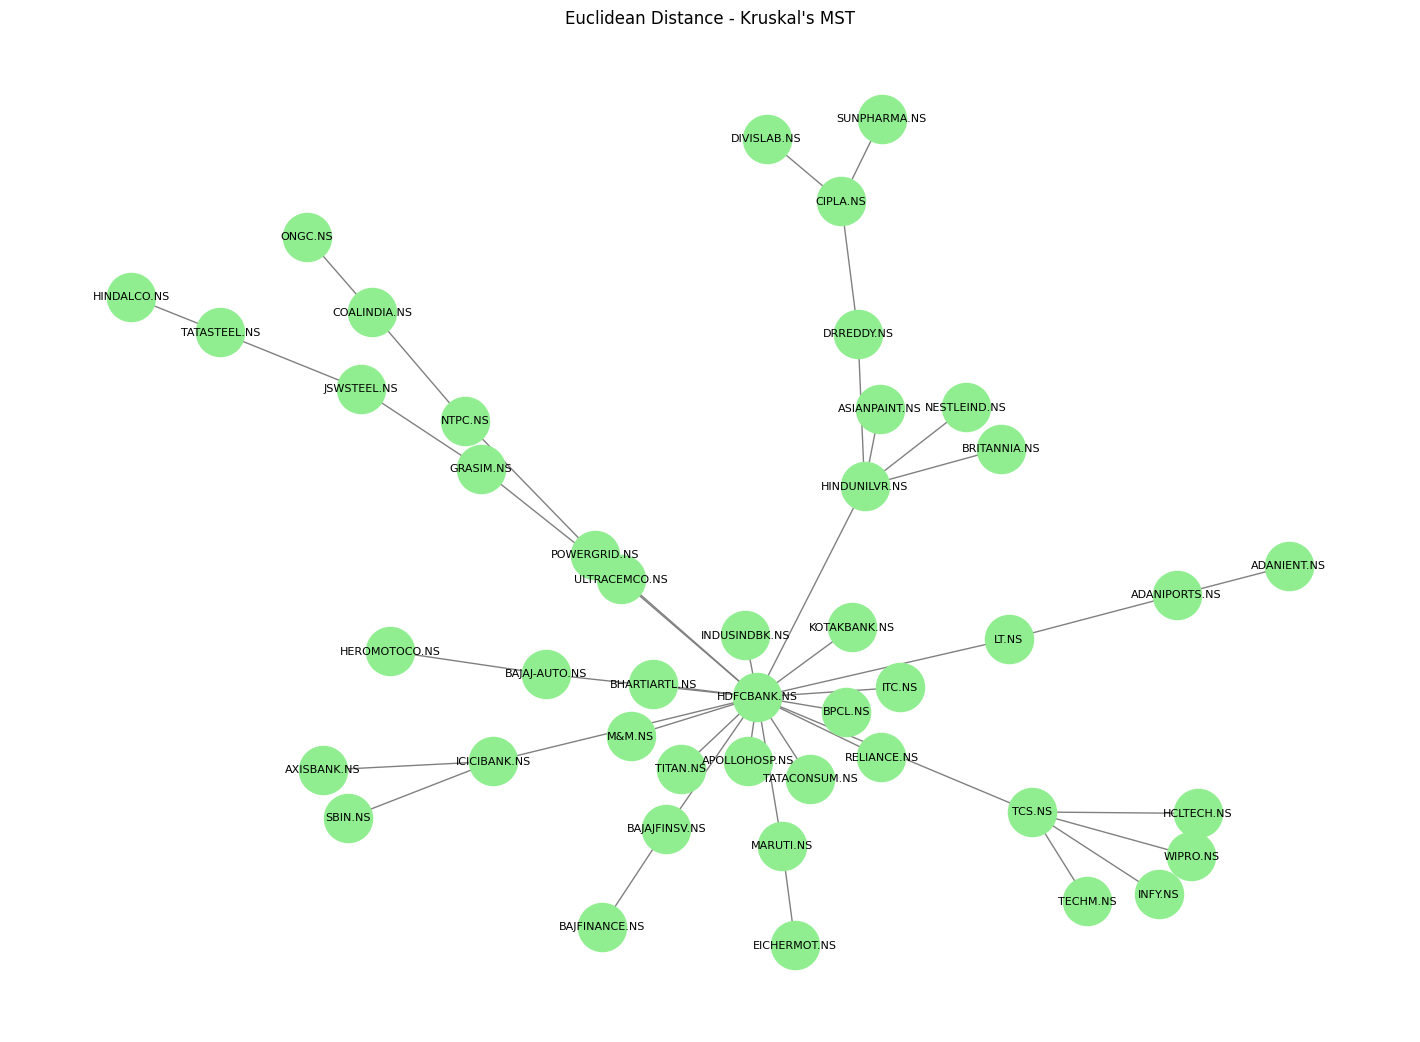

In [ ]:
plot_mst(corr_prim, "Correlation Distance - Prim's MST", "orange")
plot_mst(corr_kruskal, "Correlation Distance - Kruskal's MST", "lightgreen")

plot_mst(euclidean_prim, "Euclidean Distance - Prim's MST", "orange")
plot_mst(euclidean_kruskal, "Euclidean Distance - Kruskal's MST", "lightgreen")

(iii) Compare the resulting financial networks by identifying the highly connected/central stocks and major sector-wise connections.

In [ ]:
def analyze_mst(G, name):
  print("\n" + "="*60)
  print(name)
  print("="*60)

  # Degree
  degree = dict(G.degree())

  # Degree centrality
  degree_centrality = nx.degree_centrality(G)

  # Betweenness centrality
  betweenness = nx.betweenness_centrality(G)

  # Create table
  centrality_df = pd.DataFrame({
      "Stock": list(G.nodes()),
      "Degree": [degree[x] for x in G.nodes()],
      "Degree Centrality": [degree_centrality[x] for x in G.nodes()],
      "Betweenness Centrality": [betweenness[x] for x in G.nodes()]
  })

  # Sort by degree
  centrality_df = centrality_df.sort_values(
      "Degree",
      ascending=False
  )

  print("\nTop stocks by degree:")
  print(centrality_df.head(10).to_string(index=False))

  print("\nTop stocks by betweenness:")
  print(
      centrality_df
      .sort_values("Betweenness Centrality", ascending=False)
      .head(10)
      .to_string(index=False)
  )

  return centrality_df

In [ ]:
corr_analysis = analyze_mst(corr_prim, "Correlation Distance MST")
euc_analysis = analyze_mst(euclidean_prim, "Euclidean Distance MST")


Correlation Distance MST

Top stocks by degree:
        Stock  Degree  Degree Centrality  Betweenness Centrality
    GRASIM.NS       5           0.113636                0.631078
    MARUTI.NS       5           0.113636                0.215645
 ICICIBANK.NS       4           0.090909                0.588795
  AXISBANK.NS       4           0.090909                0.387949
HINDUNILVR.NS       3           0.068182                0.089852
  HDFCBANK.NS       3           0.068182                0.089852
      ONGC.NS       3           0.068182                0.172304
      SBIN.NS       3           0.068182                0.132135
      INFY.NS       3           0.068182                0.132135
 TATASTEEL.NS       3           0.068182                0.246300

Top stocks by betweenness:
        Stock  Degree  Degree Centrality  Betweenness Centrality
    GRASIM.NS       5           0.113636                0.631078
ULTRACEMCO.NS       3           0.068182                0.591966
 ICICIBANK.NS

In [ ]:
# Highly connected stocks → high degree
# Bridge/structurally central stocks → high betweenness

In [ ]:
# Check whether the correlation MSTs are identical
print(
    "Correlation MSTs identical:",
    nx.utils.graphs_equal(corr_prim, corr_kruskal)
)

# Check whether the Euclidean MSTs are identical
print(
    "Euclidean MSTs identical:",
    nx.utils.graphs_equal(euclidean_prim,euclidean_kruskal)
)

Correlation MSTs identical: True
Euclidean MSTs identical: True


(iv) Compare the clustering structure obtained in Question 1 with the MST structure and discuss the financial relationships among the Nifty 50 stocks.

In [ ]:
sector_map = {
    "RELIANCE.NS": "Energy",
    "TCS.NS": "IT",
    "HDFCBANK.NS": "Financials",
    "ICICIBANK.NS": "Financials",
    "INFY.NS": "IT",
    "HINDUNILVR.NS": "Consumer",
    "ITC.NS": "Consumer",
    "SBIN.NS": "Financials",
    "BHARTIARTL.NS": "Telecom",
    "KOTAKBANK.NS": "Financials",
    "LT.NS": "Industrials",
    "AXISBANK.NS": "Financials",
    "ASIANPAINT.NS": "Consumer",
    "MARUTI.NS": "Automobile",
    "TITAN.NS": "Consumer",
    "HCLTECH.NS": "IT",
    "BAJFINANCE.NS": "Financials",
    "SUNPHARMA.NS": "Healthcare",
    "ADANIENT.NS": "Industrials",
    "ULTRACEMCO.NS": "Cement",
    "TATASTEEL.NS": "Metals",
    "JSWSTEEL.NS": "Metals",
    "GRASIM.NS": "Industrials",
    "NTPC.NS": "Utilities",
    "POWERGRID.NS": "Utilities",
    "ONGC.NS": "Energy",
    "ADANIPORTS.NS": "Infrastructure",
    "HINDALCO.NS": "Metals",
    "M&M.NS": "Automobile",
    "COALINDIA.NS": "Energy",
    "BAJAJFINSV.NS": "Financials",
    "NESTLEIND.NS": "Consumer",
    "CIPLA.NS": "Healthcare",
    "DRREDDY.NS": "Healthcare",
    "APOLLOHOSP.NS": "Healthcare",
    "BRITANNIA.NS": "Consumer",
    "BPCL.NS": "Energy",
    "BAJAJ-AUTO.NS": "Automobile",
    "EICHERMOT.NS": "Automobile",
    "HEROMOTOCO.NS": "Automobile",
    "DIVISLAB.NS": "Healthcare",
    "INDUSINDBK.NS": "Financials",
    "TECHM.NS": "IT",
    "WIPRO.NS": "IT",
    "TATACONSUM.NS": "Consumer"
}

In [ ]:
def sector_connections(G, sector_map):
    connections = []
    for u, v in G.edges():
        # Put the pair in alphabetical order of sector, so A–B and B–A are counted as the same connection
        if sector_map[u] > sector_map[v]:
            u, v = v, u
        sector_u = sector_map[u]
        sector_v = sector_map[v]
        connections.append({
            "Stock 1": u,
            "Sector 1": sector_u,
            "Stock 2": v,
            "Sector 2": sector_v,
            "Same Sector": sector_u == sector_v
        })
    return pd.DataFrame(connections)


corr_sector_edges = sector_connections(corr_prim, sector_map)
euclidean_sector_edges = sector_connections(euclidean_prim, sector_map)

print("Correlation MST sector connections:")
print(
    corr_sector_edges
    .groupby(["Sector 1", "Sector 2"])
    .size()
    .sort_values(ascending=False)
)

print("\nEuclidean MST sector connections:")
print(
    euclidean_sector_edges
    .groupby(["Sector 1", "Sector 2"])
    .size()
    .sort_values(ascending=False)
)

Correlation MST sector connections:
Sector 1     Sector 2      
Financials   Financials        7
IT           IT                4
Automobile   Automobile        4
Consumer     Consumer          3
Healthcare   Healthcare        3
Energy       Energy            2
Cement       Industrials       2
Metals       Metals            2
Automobile   Financials        1
Consumer     Industrials       1
             IT                1
             Financials        1
Cement       Consumer          1
Automobile   Consumer          1
Energy       Utilities         1
             Metals            1
             Financials        1
Financials   Infrastructure    1
             Industrials       1
             Healthcare        1
Healthcare   Industrials       1
Industrials  Infrastructure    1
             Metals            1
             Telecom           1
Utilities    Utilities         1
dtype: int64

Euclidean MST sector connections:
Sector 1     Sector 2      
Financials   Financials        7
Co

#Q3

Calculate the daily return of the selected stock and consider Daily Return as the dependent variable. Compute the following regression models

In [ ]:
import pandas as pd
import numpy as np
import yfinance as yf

stock = "RELIANCE.NS"

start_date = "2014-01-01"
end_date = "2024-01-01"

data = yf.download(
    stock,
    start=start_date,
    end=end_date,
    auto_adjust=False
)

# If yfinance creates multi-level columns
if isinstance(data.columns, pd.MultiIndex):
    data.columns = data.columns.get_level_values(0)

data = data[["Open","High","Low","Close","Volume"]].copy()

data.head()

[*********************100%***********************]  1 of 1 completed


Price,Open,High,Low,Close,Volume
Date,,,,,
2014-01-01,205.141968,205.324844,202.890427,203.164734,5849398
2014-01-02,202.913284,204.810532,198.890228,200.010284,6023632
2014-01-03,199.233093,199.633118,195.438614,197.553009,12833897
2014-01-06,197.061554,197.324432,194.295700,195.427185,13315857
2014-01-07,195.347183,196.570099,192.021301,192.489899,17311470


In [ ]:
data["Return"] = data["Close"].pct_change() * 100
data["Previous_Return"] = data["Return"].shift(1)

data = data.dropna()
data.head()

Price,Open,High,Low,Close,Volume,Return,Previous_Return
Date,,,,,,,
2014-01-03,199.233093,199.633118,195.438614,197.553009,12833897,-1.228575,-1.552656
2014-01-06,197.061554,197.324432,194.295700,195.427185,13315857,-1.076078,-1.228575
2014-01-07,195.347183,196.570099,192.021301,192.489899,17311470,-1.503008,-1.076078
2014-01-08,193.015640,195.975784,193.015640,194.078552,12726430,0.825318,-1.503008
2014-01-09,194.398560,195.164322,193.164215,194.455704,8309185,0.194329,0.825318


In [ ]:
# 80% training, 20% testing
train_size = int(len(data) * 0.80)

train = data.iloc[:train_size].copy()
test = data.iloc[train_size:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

Training observations: 1970
Testing observations: 493


(a) Simple Linear Regression using the previous day return as independent variable

In [ ]:
import statsmodels.api as sm
from sklearn.metrics import mean_squared_error

# Simple Linear Regression
X_train_simple = train[["Previous_Return"]]
y_train = train["Return"]

X_train_simple = sm.add_constant(X_train_simple)

simple_model = sm.OLS(y_train,X_train_simple).fit()
print(simple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Return   R-squared:                       0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                    0.3885
Date:                Sun, 27 Sep 2026   Prob (F-statistic):              0.533
Time:                        18:45:26   Log-Likelihood:                -3981.2
No. Observations:                1970   AIC:                             7966.
Df Residuals:                    1968   BIC:                             7978.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.1043      0.041     

In [ ]:
X_test_simple = test[["Previous_Return"]]
X_test_simple = sm.add_constant(X_test_simple)

simple_predictions = simple_model.predict(X_test_simple)

simple_rmse = np.sqrt(mean_squared_error(test["Return"],simple_predictions))
print("Simple Regression Test RMSE:", round(simple_rmse, 4), "%")

Simple Regression Test RMSE: 1.4179 %


(b) Multiple Linear Regression using Previous-day return , Open price, High price, Low price, Trading Volume as independent variables

In [ ]:
features = ["Previous_Return", "Open", "High", "Low", "Volume"]

X_train_multiple = train[features]
y_train = train["Return"]

X_train_multiple = sm.add_constant(X_train_multiple)
multiple_model = sm.OLS(y_train, X_train_multiple).fit()

print(multiple_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Return   R-squared:                       0.523
Model:                            OLS   Adj. R-squared:                  0.522
Method:                 Least Squares   F-statistic:                     431.3
Date:                Sun, 27 Sep 2026   Prob (F-statistic):          8.90e-313
Time:                        18:45:30   Log-Likelihood:                -3251.6
No. Observations:                1970   AIC:                             6515.
Df Residuals:                    1964   BIC:                             6549.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                      coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -0.1921      0.068     

In [ ]:
X_test_multiple = test[features]
X_test_multiple = sm.add_constant(X_test_multiple)

multiple_predictions = multiple_model.predict(X_test_multiple)

multiple_rmse = np.sqrt(mean_squared_error(test["Return"], multiple_predictions))
print("Multiple Regression Test RMSE:", round(multiple_rmse, 4), "%")

Multiple Regression Test RMSE: 1.2732 %


ii) Autoregressive Model
Develop AR(1), AR(2), AR(3) and AR(5) models using the daily return series. Select the best AR model based on AIC/BIC and RMSE.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error

y_train = train["Return"].values
y_test = test["Return"].values
y_all = np.concatenate([y_train, y_test])
n = len(y_train)

ar_results, ar_preds = [], {}

for lag in [1, 2, 3, 5]:
    model = ARIMA(y_train, order=(lag, 0, 0), trend="c").fit()   # AR(lag)

    # One-step-ahead forecasts on the test data
    y_pred = model.append(y_test, refit=False).predict(start=n, end=n + len(y_test) - 1)

    ar_preds[f"AR({lag})"] = y_pred
    ar_results.append({
        "Model": f"AR({lag})",
        "AIC": model.aic,
        "BIC": model.bic,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred))
    })

ar_results_df = pd.DataFrame(ar_results)
print(ar_results_df)

   Model          AIC          BIC      RMSE
0  AR(1)  7968.372695  7985.130061  1.417903
1  AR(2)  7968.165033  7990.508189  1.418739
2  AR(3)  7970.076742  7998.005686  1.419361
3  AR(5)  7972.671518  8011.772040  1.416648


(iii) ARMA Model

Develop and compare the following models:
- ARMA(1,1)
- ARMA(2,1)
- ARMA(1,2)

Select the best ARMA model using AIC/BIC and RMSE.

In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

# Training and testing return series
y_train = train["Return"].values
y_test = test["Return"].values
y_all = np.concatenate([y_train, y_test])
n = len(y_train)

# Store results
arma_results, arma_preds = [], {}

# ARMA(1,1), ARMA(2,1), ARMA(1,2)
models = [(1,1), (2,1), (1,2)]

for p, q in models:
    model = ARIMA(y_train, order=(p, 0, q), trend="c").fit()

    # Predictions for test data
    y_pred = model.append(y_test, refit=False).predict(start=n, end=n + len(y_test) - 1)
    arma_preds[f"ARMA({p},{q})"] = y_pred

    # Test RMSE
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))

    arma_results.append({
        "Model": f"ARMA({p},{q})",
        "AIC": model.aic,
        "BIC": model.bic,
        "RMSE": rmse
    })

# Results table
arma_results_df = pd.DataFrame(arma_results)

print(arma_results_df)

       Model          AIC          BIC      RMSE
0  ARMA(1,1)  7969.804677  7992.147832  1.418598
1  ARMA(2,1)  7970.125525  7998.054469  1.419052
2  ARMA(1,2)  7970.036862  7997.965807  1.419042


In [ ]:
# From the result
# ARMA(1,1) is a better model
# AIC, BIC, RMSE --> Lower is better

(iv) ARIMA Model Using the daily closing-price series, develop and compare:
- ARIMA(1,1,0)
- ARIMA(0,1,1)
- ARIMA(1,1,1)
- ARIMA(2,1,1)

Perform the ADF test and appropriate differencing before fitting the models. Select the best ARIMA model using AIC/BIC and RMSE.

In [ ]:
from statsmodels.tsa.stattools import adfuller

price = data["Close"].copy()

adf_result = adfuller(price.dropna(), result_object=False)
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])

if adf_result[1] < 0.05:
    print("The closing price series is stationary.")
else:
    print("The closing price series is non-stationary.")

ADF Statistic: -0.19762106294251244
p-value: 0.9388045869516157
The closing price series is non-stationary.


In [ ]:
price_diff = price.diff().dropna()

adf_diff = adfuller(price_diff, result_object=False)
print("ADF Statistic after differencing:", adf_diff[0])
print("p-value after differencing:", adf_diff[1])

if adf_diff[1] < 0.05:
    print("The differenced series is stationary.")
else:
    print("The differenced series is still non-stationary.")

ADF Statistic after differencing: -22.36986065124652
p-value after differencing: 0.0
The differenced series is stationary.


In [ ]:
close_train = train["Close"].reset_index(drop=True)
close_test = test["Close"].reset_index(drop=True)

print("Training observations for prices:", len(close_train))
print("Testing observations for prices:", len(close_test))

Training observations for prices: 1970
Testing observations for prices: 493


In [ ]:
from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

arima_results, arima_preds = [], {}

# ARIMA(1,1,0), ARIMA(0,1,1), ARIMA(1,1,1), ARIMA(2,1,1)
models = [(1,1,0), (0,1,1), (1,1,1), (2,1,1)]

for p, d, q in models:
    model = ARIMA(close_train, order=(p, d, q)).fit()

    # Forecast the test period
    predictions = model.append(close_test.values, refit=False).predict(
        start=len(close_train), end=len(close_train) + len(close_test) - 1
    )
    arima_preds[f"ARIMA({p},{d},{q})"] = predictions

    # Test RMSE
    rmse = np.sqrt(mean_squared_error(close_test, predictions))

    arima_results.append({
        "Model": f"ARIMA({p},{d},{q})",
        "AIC": model.aic,
        "BIC": model.bic,
        "RMSE": rmse
    })

# Results table
arima_results_df = pd.DataFrame(arima_results)

print(arima_results_df)

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


          Model           AIC           BIC       RMSE
0  ARIMA(1,1,0)  14867.785063  14878.955625  16.408410
1  ARIMA(0,1,1)  14867.791472  14878.962034  16.408836
2  ARIMA(1,1,1)  14869.615625  14886.371468  16.415858
3  ARIMA(2,1,1)  14869.023543  14891.364668  16.410170


In [ ]:
# The ADF test on the closing prices gave p = 0.94, so the price series is non-stationary. After first differencing, p ≈ 0.00,
# so the differenced series is stationary; hence d = 1.
# Of the four models, ARIMA(1,1,0) has the lowest AIC (14867.79), the lowest BIC (14878.96) and the lowest test RMSE (16.41),
# so it is the best ARIMA model.
# The RMSE values of all four models are very close (16.41–16.42), which shows that the extra AR/MA terms add almost nothing.

(v) Comparison and Forecasting

Compare the best models obtained from:
1. Multiple Linear Regression
2. AR
3. ARMA
4. ARIMA

Forecast the stock movement for the test period and evaluate the forecasting performance using MAE, RMSE and MAPE. Identify the model that provides the best forecasting performance.

Best AR model:    AR(5)
Best ARMA model:  ARMA(1,1)
Best ARIMA model: ARIMA(1,1,0)

Forecast performance on the test period:
                     Model  MAE (return %)  RMSE (return %)  MAPE (price %)
Multiple Linear Regression          0.9500           1.2732          0.9502
                     AR(5)          1.0397           1.4166          1.0400
                 ARMA(1,1)          1.0424           1.4186          1.0427
              ARIMA(1,1,0)          1.0371           1.4152          1.0363

Best forecasting model (lowest RMSE): Multiple Linear Regression


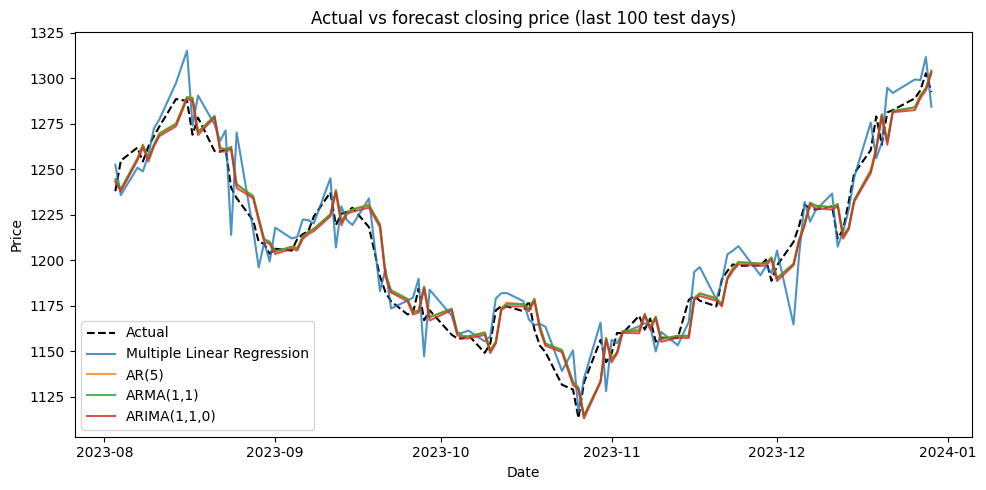

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt

# Pick the best model of each type (lowest test RMSE)
best_AR    = ar_results_df.loc[ar_results_df["RMSE"].idxmin(), "Model"]
best_ARMA  = arma_results_df.loc[arma_results_df["RMSE"].idxmin(), "Model"]
best_ARIMA = arima_results_df.loc[arima_results_df["RMSE"].idxmin(), "Model"]

print("Best AR model:   ", best_AR)
print("Best ARMA model: ", best_ARMA)
print("Best ARIMA model:", best_ARIMA)


# Actual values for the test period
actual_ret   = test["Return"].values                              # actual daily return (%)
actual_price = test["Close"].values                               # actual closing price
prev_close   = data["Close"].shift(1).loc[test.index].values      # previous day's close


# All forecasts as daily returns (%)
# ARIMA forecasts prices, so convert them to returns
arima_price_pred  = np.asarray(arima_preds[best_ARIMA])
arima_return_pred = (arima_price_pred / prev_close - 1) * 100

forecast_returns = {
    "Multiple Linear Regression": np.asarray(multiple_predictions),
    best_AR:    np.asarray(ar_preds[best_AR]),
    best_ARMA:  np.asarray(arma_preds[best_ARMA]),
    best_ARIMA: arima_return_pred,
}


# Evaluate: MAE, RMSE (on returns), MAPE (on prices)
rows = []
forecast_prices = {}

for name, r in forecast_returns.items():
    price_pred = prev_close * (1 + r / 100)      # predicted return -> predicted price
    forecast_prices[name] = price_pred

    rows.append({
        "Model": name,
        "MAE (return %)":  mean_absolute_error(actual_ret, r),
        "RMSE (return %)": np.sqrt(mean_squared_error(actual_ret, r)),
        "MAPE (price %)":  np.mean(np.abs((actual_price - price_pred) / actual_price)) * 100
    })

final_comparison = pd.DataFrame(rows)
print("\nForecast performance on the test period:")
print(final_comparison.round(4).to_string(index=False))

best_model = final_comparison.loc[final_comparison["RMSE (return %)"].idxmin(), "Model"]
print("\nBest forecasting model (lowest RMSE):", best_model)


# Plot actual vs forecast prices (last 100 test days)
last = 100
plt.figure(figsize=(10, 5))
plt.plot(test.index[-last:], actual_price[-last:], label="Actual", color="black", linestyle='--')
for name, p in forecast_prices.items():
    plt.plot(test.index[-last:], p[-last:], label=name, alpha=0.8)
plt.title(f"Actual vs forecast closing price (last {last} test days)")
plt.xlabel("Date"); plt.ylabel("Price")
plt.legend()
plt.tight_layout()
plt.show()